# 酒店预订客户聚类分群：K-Means、DBSCAN 与层次聚类对比

**香港城市大学 MSc Electronic Commerce · IS6400 课程项目（个人完成） · Notebook 4/4**

先在 Iris 数据集上对比 K-Means、二分 K-Means、DBSCAN 及四种 linkage 的层次聚类；随后在 Hotel Booking Demand 数据集上选取 13 个预订行为特征，结合肘部法则与轮廓系数确定 K 值，使用 K-Means 对约 12 万条订单进行客户分群，并刻画各类客群的预订行为画像。

- KMeans

In [1]:
import warnings
import os
warnings.filterwarnings("ignore")
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

iris = pd.read_csv(
    '../data/iris.txt',
    header=None,
    names=['sepal length', 'sepal width', 'petal length', 'petal width', 'class']
)
iris.head()
data = iris.drop('class', axis=1)
k_means = KMeans(n_clusters=3, max_iter=50, random_state=1)
k_means.fit(data)
labels = k_means.labels_
pd.DataFrame(labels, index=data.index, columns=['Cluster ID'])
pd.Series(labels).value_counts().sort_index()

0    61
1    50
2    39
Name: count, dtype: int64

KMeans divided the Iris dataset into 3 clusters. The three clusters contain 61, 50, and 39 data points, respectively.

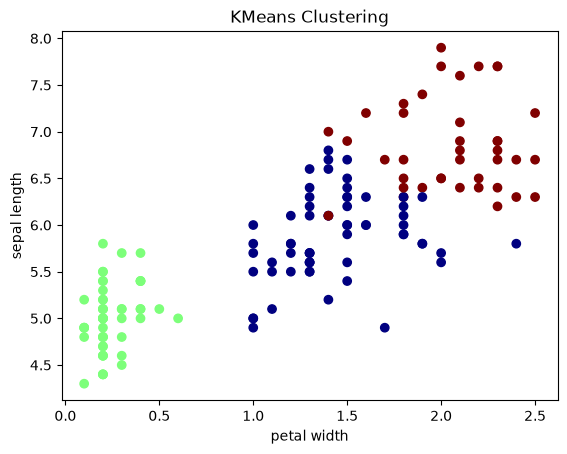

In [2]:
plt.scatter(iris['petal width'], iris['sepal length'], c=labels, cmap='jet')
plt.xlabel('petal width')
plt.ylabel('sepal length')
plt.title('KMeans Clustering')
plt.show()

The scatter plot shows the distribution of the three clusters based on petal width and sepal length.

- BisectingKMeans

In [3]:
from sklearn.cluster import BisectingKMeans
data = iris.drop('class', axis=1)
bisect_kmeans = BisectingKMeans(n_clusters=3, max_iter=50, random_state=1).fit(data)
labels = bisect_kmeans.labels_
pd.Series(labels).value_counts().sort_index()

0    53
1    38
2    59
Name: count, dtype: int64

BisectingKMeans divided the Iris dataset into 3 clusters. The three clusters contain 53, 38, and 59 data points, respectively.

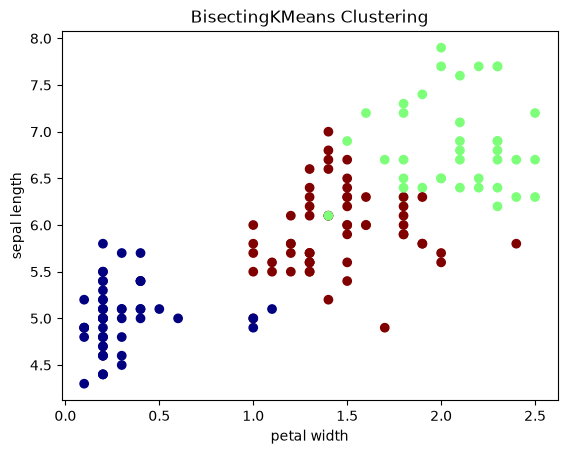

In [4]:
plt.scatter(data['petal width'],data['sepal length'],c=labels,cmap='jet')
plt.xlabel('petal width')
plt.ylabel('sepal length')
plt.title('BisectingKMeans Clustering')
plt.show()

Normal KMeans tries to select cluster centers, with K=3 in this case. It continues the process of assigning points, updating centroids, and repeating these steps, which means the method tries to find 3 final clusters.

BisectingKMeans uses a divisive hierarchical clustering method. It starts with all data points in one cluster and repeatedly splits a cluster into two smaller clusters until it reaches 3 final clusters.

- Density-Based Clusting

In [5]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

data = iris.drop('class', axis=1)
data_scaled = StandardScaler().fit_transform(data)

#parameter tuning
for eps in [0.5, 0.6, 0.7, 0.8, 0.9, 1.0]:
    db = DBSCAN(eps=eps, min_samples=5).fit(data_scaled)
    labels = db.labels_
    n_noise = (labels == -1).sum()
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    print(
        f"eps={eps}: "
        f"clusters={n_clusters}, "
        f"noise points={n_noise}"
    )

eps=0.5: clusters=2, noise points=35
eps=0.6: clusters=2, noise points=26
eps=0.7: clusters=2, noise points=8
eps=0.8: clusters=2, noise points=4
eps=0.9: clusters=2, noise points=4
eps=1.0: clusters=2, noise points=3


Based on the tuning results, eps = 0.8 was selected because, with min_samples = 5, it provides a reasonable balance between the number of clusters and the number of noise points. The final result consists of 2 clusters and only 4 noise points. Therefore, eps = 0.8 was chosen as the final parameter.

In [6]:
db = DBSCAN(eps=0.8, min_samples=5).fit(data_scaled)
labels = pd.DataFrame(db.labels_, columns=['Cluster ID'])
result = pd.concat((iris.drop('class', axis=1), labels), axis=1)
result.head()
#calculate noise
noise_points = (db.labels_ == -1).sum()
print("Number of noise points:", noise_points)

Number of noise points: 4


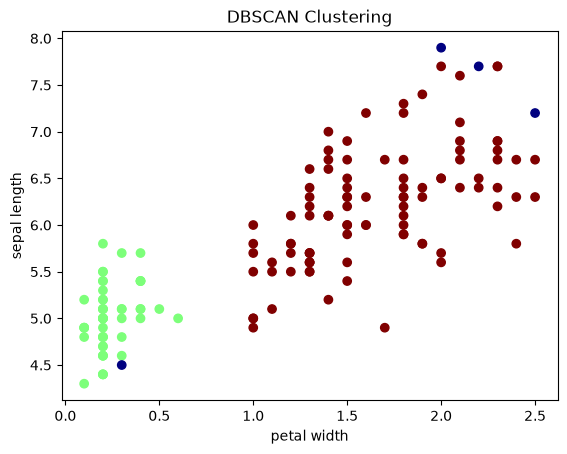

In [7]:
plt.scatter(data['petal width'], data['sepal length'], c=db.labels_, cmap='jet')
plt.xlabel('petal width')
plt.ylabel('sepal length')
plt.title('DBSCAN Clustering')
plt.show()

DBSCAN divided the Iris dataset into 2 clusters and identified 4 data points as noise. The final parameters were eps = 0.8 and min_samples = 5.

- Comparing Hierarchical Clustering Linkage Methods

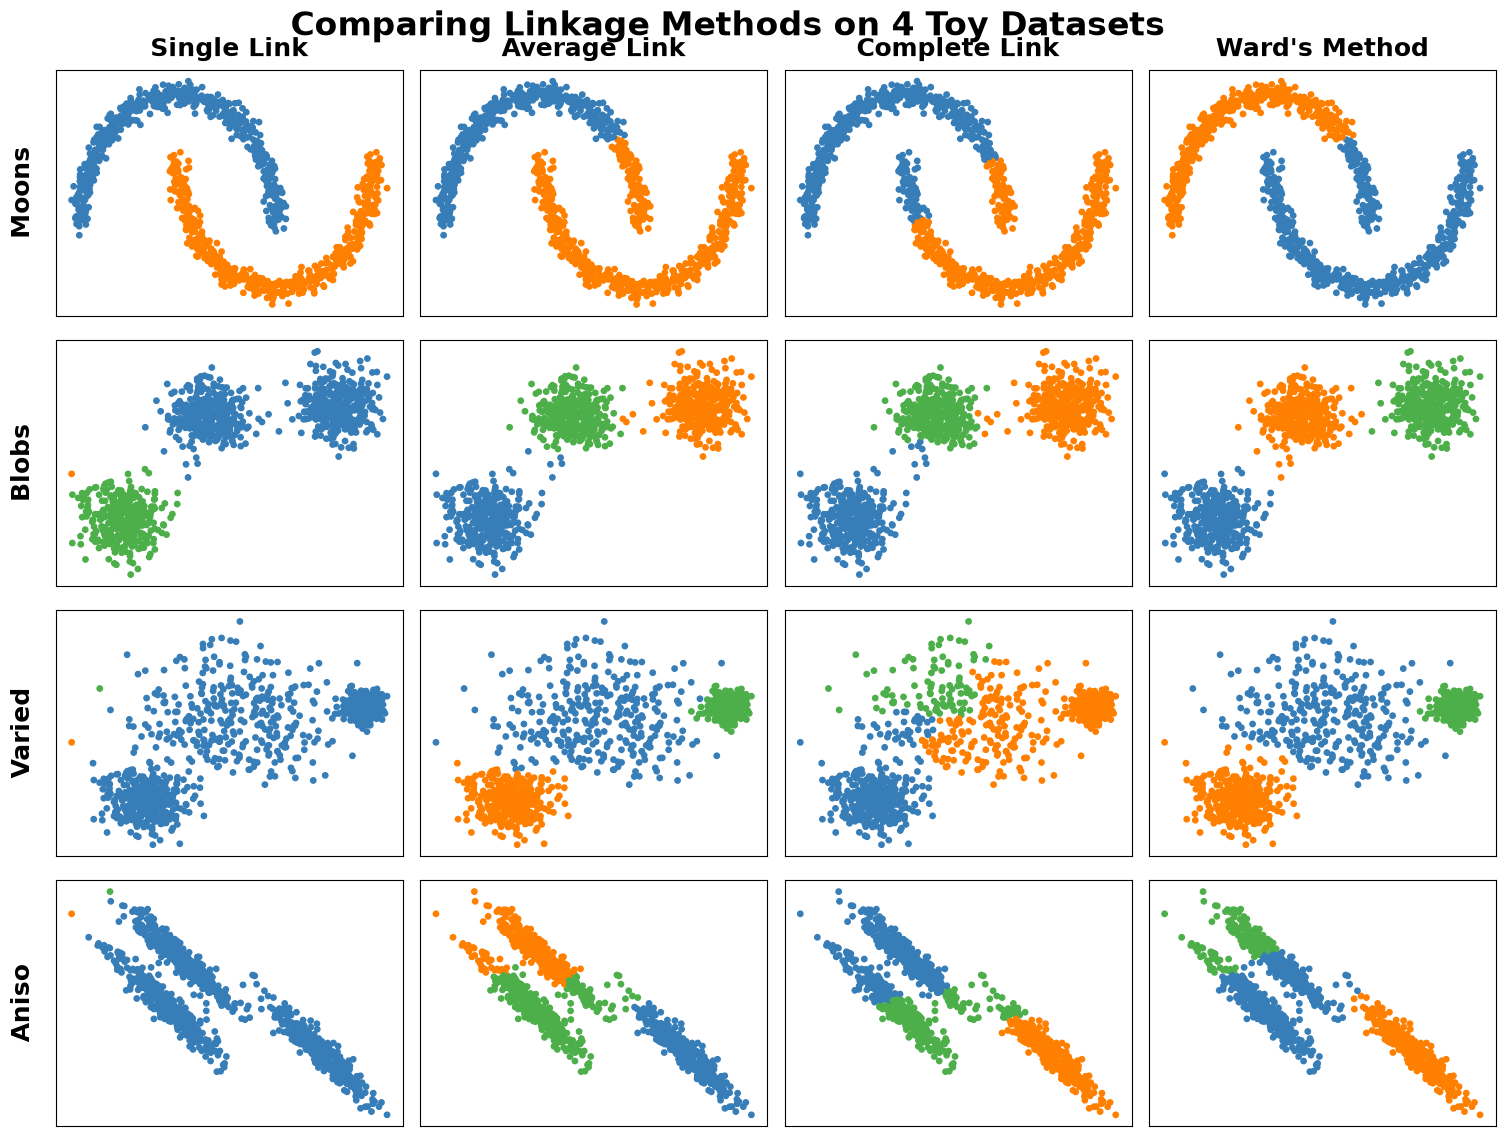

In [8]:
#code in in Section 2.5
import warnings
from itertools import cycle, islice
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

# 1. Generate 4 selected datasets
n_samples = 1000
moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=170)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=170)
varied = datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=170)
X, _ = datasets.make_blobs(n_samples=n_samples, random_state=170)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)

datasets = [
    ("Moons", moons[0], 2),
    ("Blobs", blobs[0], 3),
    ("Varied", varied[0], 3),
    ("Aniso", X_aniso, 3)
]

# 2. Set up the plot
plt.figure(figsize=(16, 12))
plt.subplots_adjust(left=0.08, right=0.98, bottom=0.02, top=0.90, wspace=0.05, hspace=0.1)

plot_num = 1
algorithms = ["Single Link", "Average Link", "Complete Link", "Ward's Method"]

# 3. Loop through datasets and algorithms
for i, (name, X, n_clusters) in enumerate(datasets):
    X = StandardScaler().fit_transform(X)

    clustering_algorithms = (
        ("Single Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="single")),
        ("Average Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="average")),
        ("Complete Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="complete")),
        ("Ward's Method", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")),
    )

    for j, (algo_name, algorithm) in enumerate(clustering_algorithms):
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore")
            algorithm.fit(X)

        y_pred = algorithm.labels_.astype(int)
        ax = plt.subplot(len(datasets), len(clustering_algorithms), plot_num)

        if i == 0:
            ax.set_title(algo_name, size=18, fontweight='bold', pad=10)
        if j == 0:
            ax.set_ylabel(name, size=18, fontweight='bold', labelpad=15)

        colors = np.array(list(islice(cycle(["#377eb8", "#ff7f00", "#4daf4a", "#f781bf"]), int(max(y_pred) + 1))))
        ax.scatter(X[:, 0], X[:, 1], s=15, color=colors[y_pred])
        ax.set_xticks(()); ax.set_yticks(())

        plot_num += 1

plt.suptitle("Comparing Linkage Methods on 4 Toy Datasets", fontsize=24, y=0.95, fontweight='bold')
plt.show()

The grid in Section 2.5 shows that no single linkage method works best for all four datasets, the suitable method depends on the shape and structure of the data.

For Moons, Single Link is the best choice. The two clusters are curved and non-convex, and since Single Link merges clusters using the minimum distance between points, it can follow the crescent shape rather than cutting across it. The other methods are more likely to split the curved clusters.

Blobs is the clearest case for Ward's Method. The clusters are compact and roughly spherical, which suits Ward's variance-minimising behaviour and gives the cleanest separation in the grid.

Average Link works better for both Varied and Aniso. The Varied clusters differ in spread (standard deviations of 1.0, 2.5 and 0.5), while the Aniso clusters are elongated after the transformation — Average Link handles both reasonably, whereas Ward's struggles more with the elongated shape.

In short, choose the method based on the data: Single Link for curved or non-convex clusters, Ward's for compact spherical ones, and Average Link when clusters differ in spread or are elongated.

- K-means Clustering on the Hotel Booking Dataset

For the Hotel Booking dataset, I would choose K-Means. The dataset has around 119,000 booking records, and many of the features describing booking behaviour, such as lead time, length of stay, number of guests, ADR and special requests, are numerical. After encoding the categorical variables and standardising the numerical ones, the data can be used with a distance-based method.

The large size of the dataset makes hierarchical clustering less suitable: at this scale, calculating and storing the distance matrix would be very expensive, while K-Means is designed to handle large datasets. DBSCAN is another possible option, but it is sensitive to parameters such as eps and min_samples, and it can also become less suitable after encoding the categorical variables because the feature space may become high-dimensional.

I would use K-Means to cluster the bookings and then look at the characteristics of each cluster to understand the different booking patterns.

In [9]:
import warnings
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore")
os.environ['LOKY_MAX_CPU_COUNT'] = '1'

hotel = pd.read_csv('../data/hotel_bookings.csv')
attributes = ['lead_time','stays_in_weekend_nights','stays_in_week_nights','adults','children','babies','booking_changes','previous_cancellations','previous_bookings_not_canceled','days_in_waiting_list','adr','required_car_parking_spaces','total_of_special_requests']
data = hotel[attributes].copy()

# Replace missing values in children with the median
data['children'] = data['children'].fillna(data['children'].median())
scaler = StandardScaler()
data_scaled = scaler.fit_transform(data)
data_scaled[:5]

# Apply K-means for different numbers of clusters
k_values = range(2, 9)
inertia = []
silhouette = []
for k in k_values:
    k_means = KMeans(n_clusters=k, max_iter=50, random_state=1, n_init=10)
    cluster_labels = k_means.fit_predict(data_scaled)
    inertia.append(k_means.inertia_)
    silhouette.append(silhouette_score(data_scaled, cluster_labels, sample_size=10000, random_state=42))

print("K\tInertia\t\tSilhouette Score")
for k, i, s in zip(k_values, inertia, silhouette):
    print(f"{k}\t{i:.2f}\t{s:.4f}")

K	Inertia		Silhouette Score
2	1425212.18	0.2013
3	1315923.34	0.1923
4	1220223.86	0.1965
5	1130442.92	0.1752
6	1041813.92	0.1930
7	975912.90	0.1997
8	889207.50	0.1736


Select K=2: K = 2 has the highest value of approximately 0.2013. Therefore, I select K = 2 for the final K-means model.

In [10]:
k_means = KMeans(n_clusters=2,max_iter=50,random_state=1,n_init=10)
cluster_labels = k_means.fit_predict(data_scaled)
hotel['Cluster ID'] = cluster_labels
print(hotel['Cluster ID'].value_counts().sort_index())
#back to original scale
centres = scaler.inverse_transform(k_means.cluster_centers_)
centres = pd.DataFrame(centres, columns=attributes)
centres.index.name = 'Cluster ID'
centres.round(2)

Cluster ID
0    82686
1    36704
Name: count, dtype: int64


,lead_time,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,booking_changes,previous_cancellations,previous_bookings_not_canceled,days_in_waiting_list,adr,required_car_parking_spaces,total_of_special_requests
Cluster ID,,,,,,,,,,,,,
0,105.54,0.66,1.98,1.75,0.01,0.00,0.15,0.12,0.19,3.33,86.80,0.04,0.30
1,100.59,1.53,3.67,2.09,0.32,0.02,0.38,0.01,0.03,0.05,135.54,0.12,1.18


Cluster 0 contains 82,686 bookings. Its average length of stay is relatively shorter, with about 0.66 weekend nights and 1.98 week nights. The average ADR is approximately 86.80, and the average number of special requests is 0.31.

Cluster 1 contains 36,704 bookings. It has longer stays, with about 1.53 weekend nights and 3.67 week nights. Its average ADR is approximately 135.54, and it has more adults, children, booking changes, and special requests than Cluster 0.

Therefore, the K-means model identifies two groups of hotel bookings with different booking and stay characteristics.